<a href="https://colab.research.google.com/github/aishahifritcd24-star/DLG_lab/blob/main/lab_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
covertype = fetch_ucirepo(id=31)

# data (as pandas dataframes)
X = covertype.data.features
y = covertype.data.targets

# metadata
print(covertype.metadata)

# variable information
print(covertype.variables)


{'uci_id': 31, 'name': 'Covertype', 'repository_url': 'https://archive.ics.uci.edu/dataset/31/covertype', 'data_url': 'https://archive.ics.uci.edu/static/public/31/data.csv', 'abstract': 'Classification of pixels into 7 forest cover types based on attributes such as elevation, aspect, slope, hillshade, soil-type, and more.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 581012, 'num_features': 54, 'feature_types': ['Categorical', 'Integer'], 'demographics': [], 'target_col': ['Cover_Type'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1998, 'last_updated': 'Sat Mar 16 2024', 'dataset_doi': '10.24432/C50K5N', 'creators': ['Jock Blackard'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting forest cover type from cartographic variables only (no remotely sensed data).  The actual forest cover type for a given observation (30 x 30 meter cell) was determined from

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report


In [4]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 rows of X:")
display(X.head())

print("\nFirst 5 rows of y:")
display(y.head())


X shape: (581012, 54)
y shape: (581012, 1)

First 5 rows of X:


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,0
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,0
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,0
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,0
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,0



First 5 rows of y:


,Cover_Type
0,5
1,5
2,2
3,2
4,5


In [5]:
print(y.columns)


Index(['Cover_Type'], dtype='object')


In [6]:
print(y.iloc[:, 0].unique())


[5 2 1 7 3 6 4]


In [7]:
class_counts = y.iloc[:, 0].value_counts().sort_index()

print(class_counts)

Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64


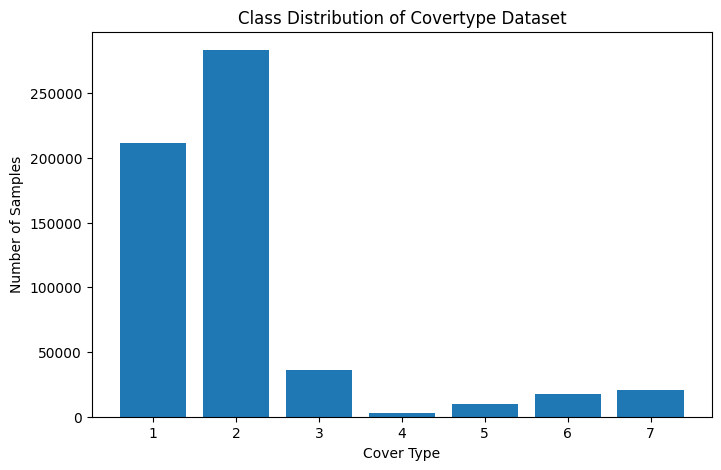

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(class_counts.index, class_counts.values)

plt.xlabel("Cover Type")
plt.ylabel("Number of Samples")
plt.title("Class Distribution of Covertype Dataset")

plt.xticks(range(1, 8))

plt.show()

In [9]:
max_count = class_counts.max()
min_count = class_counts.min()

imbalance_ratio = max_count / min_count

print("Most frequent class:", class_counts.idxmax())
print("Most frequent count:", max_count)

print("Least frequent class:", class_counts.idxmin())
print("Least frequent count:", min_count)

print("Imbalance ratio:", imbalance_ratio)

Most frequent class: 2
Most frequent count: 283301
Least frequent class: 4
Least frequent count: 2747
Imbalance ratio: 103.13105205678923


In [10]:
X = X.values
y = y.values.ravel()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (581012, 54)
y shape: (581012,)


In [11]:
y = y - 1

print("Classes after conversion:")
print(np.unique(y))

Classes after conversion:
[0 1 2 3 4 5 6]


In [12]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [13]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

In [14]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (464809, 54) (464809,)
Validation: (58101, 54) (58101,)
Testing: (58102, 54) (58102,)


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

X_test = scaler.transform(X_test)

In [16]:
num_classes = 7

y_train_onehot = np.eye(num_classes)[y_train]
y_val_onehot = np.eye(num_classes)[y_val]
y_test_onehot = np.eye(num_classes)[y_test]
print(y_train_onehot.shape)
print(y_train_onehot[:5])


(464809, 7)
[[0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0.]]


In [17]:
N = len(y_train)
K = 7

class_counts_train = np.bincount(y_train)

class_weights = N / (K * class_counts_train)

print("Class weights:")
for i, weight in enumerate(class_weights):
    print(f"Class {i}: {weight:.4f}")


Class weights:
Class 0: 0.3918
Class 1: 0.2930
Class 2: 2.3215
Class 3: 30.2099
Class 4: 8.7439
Class 5: 4.7791
Class 6: 4.0469


In [18]:
print(X.shape)
print(y.shape)
print(class_counts)
print(class_weights)


(581012, 54)
(581012,)
Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64
[ 0.39181272  0.29298132  2.32147976 30.20986611  8.74391437  4.77913385
  4.04688479]


In [19]:
input_size = 54
hidden1_size = 64
hidden2_size = 32
hidden3_size = 16
output_size = 7

np.random.seed(42)

W1 = np.random.randn(input_size, hidden1_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden1_size))

W2 = np.random.randn(hidden1_size, hidden2_size) * np.sqrt(2 / hidden1_size)
b2 = np.zeros((1, hidden2_size))

W3 = np.random.randn(hidden2_size, hidden3_size) * np.sqrt(2 / hidden2_size)
b3 = np.zeros((1, hidden3_size))

W4 = np.random.randn(hidden3_size, output_size) * np.sqrt(2 / hidden3_size)
b4 = np.zeros((1, output_size))

print("Network initialized!")
print("W1:", W1.shape)
print("W2:", W2.shape)
print("W3:", W3.shape)
print("W4:", W4.shape)

Network initialized!
W1: (54, 64)
W2: (64, 32)
W3: (32, 16)
W4: (16, 7)


In [20]:
def relu(x):
    return np.maximum(0, x)


def relu_derivative(x):
    return (x > 0).astype(float)


In [21]:
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)

    exp_z = np.exp(z)

    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


In [22]:
def forward(X):

    # Layer 1
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    # Layer 2
    Z2 = A1 @ W2 + b2
    A2 = relu(Z2)

    # Layer 3
    Z3 = A2 @ W3 + b3
    A3 = relu(Z3)

    # Output layer
    Z4 = A3 @ W4 + b4
    A4 = softmax(Z4)

    cache = (X, Z1, A1, Z2, A2, Z3, A3, Z4, A4)

    return A4, cache


In [23]:
sample_X = X_train[:5]

sample_output, cache = forward(sample_X)

print("Output shape:", sample_output.shape)
print("\nProbabilities:")
print(sample_output)

print("\nProbability sums:")
print(np.sum(sample_output, axis=1))


Output shape: (5, 7)

Probabilities:
[[1.42394448e-01 9.73233487e-02 9.64823103e-02 1.33575213e-01
  9.27991926e-02 1.30053928e-01 3.07371559e-01]
 [1.64085254e-01 1.25844619e-01 2.05537153e-01 1.09621837e-01
  1.09694787e-01 1.52321281e-01 1.32895070e-01]
 [2.73580010e-02 1.98028380e-03 1.69852012e-03 5.85377865e-02
  4.60181852e-04 2.24895756e-03 9.07716269e-01]
 [1.25583571e-01 1.55310747e-01 1.40146564e-01 1.38608486e-01
  1.12742432e-01 1.51057480e-01 1.76550719e-01]
 [1.01835422e-01 1.73128731e-01 1.98398023e-01 2.06385445e-01
  5.46590532e-02 1.14433524e-01 1.51159801e-01]]

Probability sums:
[1. 1. 1. 1. 1.]


In [24]:
def weighted_cross_entropy(y_true, y_pred, class_weights):

    # Find the class index for each sample
    class_indices = np.argmax(y_true, axis=1)

    # Get weight for each sample
    sample_weights = class_weights[class_indices]

    # Probability assigned to the correct class
    correct_probs = np.sum(y_true * y_pred, axis=1)

    # Avoid log(0)
    correct_probs = np.clip(correct_probs, 1e-12, 1.0)

    # Weighted loss
    loss = -np.sum(
        sample_weights * np.log(correct_probs)
    ) / np.sum(sample_weights)

    return loss


In [25]:
sample_y = y_train_onehot[:5]

loss = weighted_cross_entropy(
    sample_y,
    sample_output,
    class_weights
)

print("Sample weighted loss:", loss)


Sample weighted loss: 2.0270800544660816


In [26]:
def backward(cache, y_true, y_pred, class_weights):

    global W1, W2, W3, W4
    global b1, b2, b3, b4

    X, Z1, A1, Z2, A2, Z3, A3, Z4, A4 = cache

    batch_size = X.shape[0]

    # Weight for each sample
    class_indices = np.argmax(y_true, axis=1)
    sample_weights = class_weights[class_indices]

    # Reshape weights so broadcasting works
    sample_weights = sample_weights.reshape(-1, 1)

    # Gradient of weighted softmax cross-entropy
    dZ4 = (A4 - y_true) * sample_weights

    # Normalize by total weight
    dZ4 = dZ4 / np.sum(sample_weights)

    # Output layer gradients
    dW4 = A3.T @ dZ4
    db4 = np.sum(dZ4, axis=0, keepdims=True)

    # Layer 3
    dA3 = dZ4 @ W4.T
    dZ3 = dA3 * relu_derivative(Z3)

    dW3 = A2.T @ dZ3
    db3 = np.sum(dZ3, axis=0, keepdims=True)

    # Layer 2
    dA2 = dZ3 @ W3.T
    dZ2 = dA2 * relu_derivative(Z2)

    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Layer 1
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * relu_derivative(Z1)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2, dW3, db3, dW4, db4


In [27]:
batch_size = 128
learning_rate = 0.01


In [28]:
epochs = 50
patience = 15


In [29]:
batch_size = 128
learning_rate = 0.01

epochs = 50
patience = 15

print("Batch size:", batch_size)
print("Learning rate:", learning_rate)
print("Maximum epochs:", epochs)
print("Early stopping patience:", patience)


Batch size: 128
Learning rate: 0.01
Maximum epochs: 50
Early stopping patience: 15


In [30]:
# History
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# Early stopping variables
best_val_loss = float("inf")
best_params = None
wait = 0

# Training
for epoch in range(epochs):

    # Shuffle training data
    indices = np.random.permutation(len(X_train))

    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train_onehot[indices]

    epoch_loss = 0
    num_batches = 0

    # Mini-batch training
    for start in range(0, len(X_train), batch_size):

        end = start + batch_size

        X_batch = X_train_shuffled[start:end]
        y_batch = y_train_shuffled[start:end]

        # Forward propagation
        y_pred, cache = forward(X_batch)

        # Calculate loss
        loss = weighted_cross_entropy(
            y_batch,
            y_pred,
            class_weights
        )

        epoch_loss += loss
        num_batches += 1

        # Backpropagation
        gradients = backward(
            cache,
            y_batch,
            y_pred,
            class_weights
        )

        dW1, db1, dW2, db2, dW3, db3, dW4, db4 = gradients

        # Update weights
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W3 -= learning_rate * dW3
        b3 -= learning_rate * db3

        W4 -= learning_rate * dW4
        b4 -= learning_rate * db4

    # Average training loss
    train_loss = epoch_loss / num_batches

    # Training predictions
    train_probs, _ = forward(X_train)
    train_pred = np.argmax(train_probs, axis=1)

    train_accuracy = np.mean(
        train_pred == y_train
    )

    # Validation predictions
    val_probs, _ = forward(X_val)

    val_loss = weighted_cross_entropy(
        y_val_onehot,
        val_probs,
        class_weights
    )

    val_pred = np.argmax(val_probs, axis=1)

    val_accuracy = np.mean(
        val_pred == y_val
    )

    # Save history
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Print progress
    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # Early stopping
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        wait = 0

        # Save best parameters
        best_params = {
            "W1": W1.copy(),
            "b1": b1.copy(),
            "W2": W2.copy(),
            "b2": b2.copy(),
            "W3": W3.copy(),
            "b3": b3.copy(),
            "W4": W4.copy(),
            "b4": b4.copy()
        }

    else:
        wait += 1

        if wait >= patience:
            print("\nEarly stopping triggered!")
            break


Epoch 1/50 | Train Loss: 0.9198 | Val Loss: 0.7035 | Train Acc: 0.5959 | Val Acc: 0.5946
Epoch 2/50 | Train Loss: 0.6654 | Val Loss: 0.6419 | Train Acc: 0.6169 | Val Acc: 0.6171
Epoch 3/50 | Train Loss: 0.6103 | Val Loss: 0.5842 | Train Acc: 0.6486 | Val Acc: 0.6488
Epoch 4/50 | Train Loss: 0.5798 | Val Loss: 0.5728 | Train Acc: 0.6844 | Val Acc: 0.6857
Epoch 5/50 | Train Loss: 0.5541 | Val Loss: 0.5537 | Train Acc: 0.6858 | Val Acc: 0.6861
Epoch 6/50 | Train Loss: 0.5369 | Val Loss: 0.5219 | Train Acc: 0.6861 | Val Acc: 0.6883
Epoch 7/50 | Train Loss: 0.5196 | Val Loss: 0.5409 | Train Acc: 0.7061 | Val Acc: 0.7078
Epoch 8/50 | Train Loss: 0.5059 | Val Loss: 0.4949 | Train Acc: 0.6822 | Val Acc: 0.6832
Epoch 9/50 | Train Loss: 0.4940 | Val Loss: 0.4903 | Train Acc: 0.7125 | Val Acc: 0.7139
Epoch 10/50 | Train Loss: 0.4823 | Val Loss: 0.4725 | Train Acc: 0.7181 | Val Acc: 0.7201
Epoch 11/50 | Train Loss: 0.4710 | Val Loss: 0.4751 | Train Acc: 0.7135 | Val Acc: 0.7161
Epoch 12/50 | Train

In [31]:
W1 = best_params["W1"]
b1 = best_params["b1"]

W2 = best_params["W2"]
b2 = best_params["b2"]

W3 = best_params["W3"]
b3 = best_params["b3"]

W4 = best_params["W4"]
b4 = best_params["b4"]

print("Best model restored.")


Best model restored.


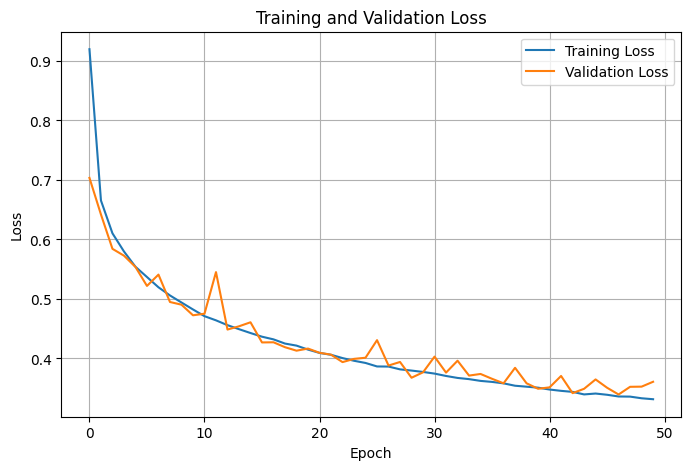

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()


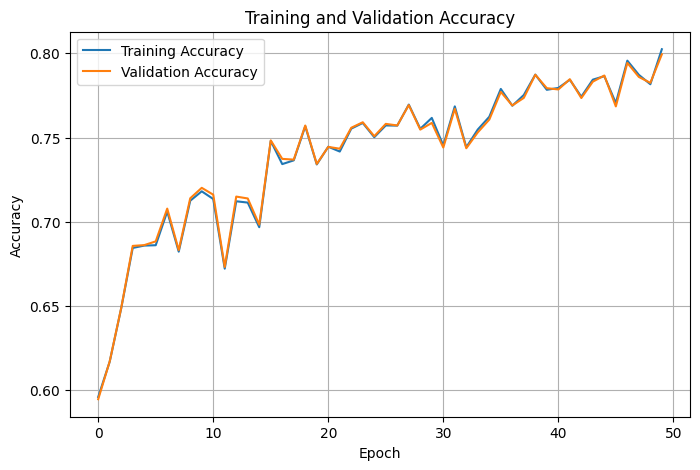

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()


In [34]:
test_probs, _ = forward(X_test)

y_pred = np.argmax(test_probs, axis=1)

print("Test probability shape:", test_probs.shape)
print("Predicted labels shape:", y_pred.shape)
print("\nFirst 10 predictions:")
print(y_pred[:10])

Test probability shape: (58102, 7)
Predicted labels shape: (58102,)

First 10 predictions:
[0 1 1 1 5 1 1 1 1 0]


In [35]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")


Test Accuracy: 0.7923
Test Accuracy: 79.23%


In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(
    y_test,
    y_pred,
    average=None,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average=None,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average=None,
    zero_division=0
)

print("Per-class metrics:\n")

for i in range(7):
    print(
        f"Class {i}: "
        f"Precision = {precision[i]:.4f}, "
        f"Recall = {recall[i]:.4f}, "
        f"F1 = {f1[i]:.4f}"
    )


Per-class metrics:

Class 0: Precision = 0.7993, Recall = 0.7967, F1 = 0.7980
Class 1: Precision = 0.8640, Recall = 0.7631, F1 = 0.8104
Class 2: Precision = 0.7997, Recall = 0.8073, F1 = 0.8035
Class 3: Precision = 0.5187, Recall = 0.9635, F1 = 0.6743
Class 4: Precision = 0.3684, Recall = 0.9442, F1 = 0.5300
Class 5: Precision = 0.5817, Recall = 0.8543, F1 = 0.6922
Class 6: Precision = 0.7005, Recall = 0.9771, F1 = 0.8160


In [37]:
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Macro F1 Score: {macro_f1:.4f}")


Macro F1 Score: 0.7321


In [38]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Class 0",
            "Class 1",
            "Class 2",
            "Class 3",
            "Class 4",
            "Class 5",
            "Class 6"
        ],
        zero_division=0
    )
)


              precision    recall  f1-score   support

     Class 0       0.80      0.80      0.80     21184
     Class 1       0.86      0.76      0.81     28331
     Class 2       0.80      0.81      0.80      3576
     Class 3       0.52      0.96      0.67       274
     Class 4       0.37      0.94      0.53       949
     Class 5       0.58      0.85      0.69      1737
     Class 6       0.70      0.98      0.82      2051

    accuracy                           0.79     58102
   macro avg       0.66      0.87      0.73     58102
weighted avg       0.81      0.79      0.80     58102



In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[16878  3322    24     0   190    21   749]
 [ 4192 21620   494     3  1291   623   108]
 [    0    34  2887   197    49   409     0]
 [    0     0     5   264     0     5     0]
 [    0    34    10     0   896     9     0]
 [    0    12   190    45     6  1484     0]
 [   45     2     0     0     0     0  2004]]


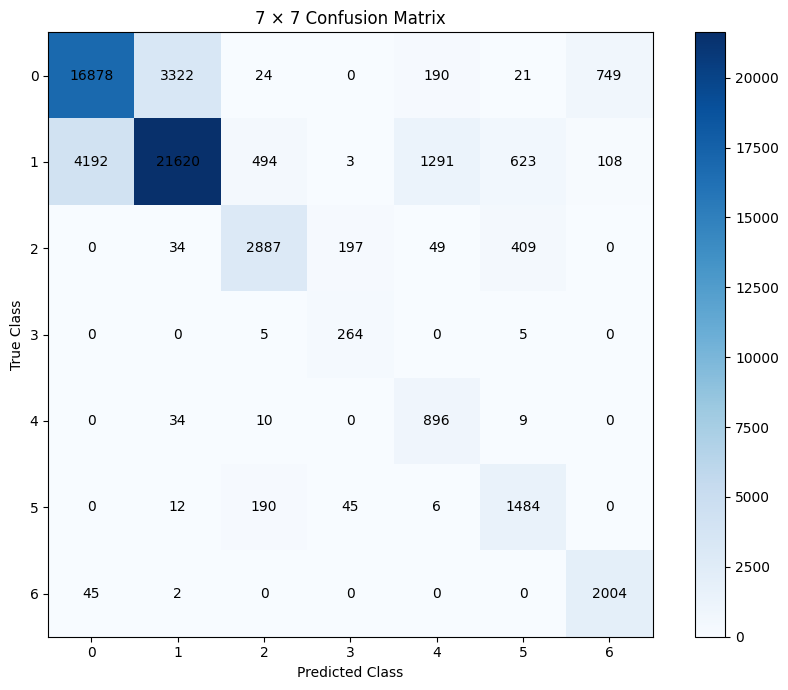

In [40]:
plt.figure(figsize=(9, 7))

plt.imshow(cm, cmap="Blues")

plt.colorbar()

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("7 × 7 Confusion Matrix")

plt.xticks(range(7), range(7))
plt.yticks(range(7), range(7))

# Add numbers inside cells
for i in range(7):
    for j in range(7):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


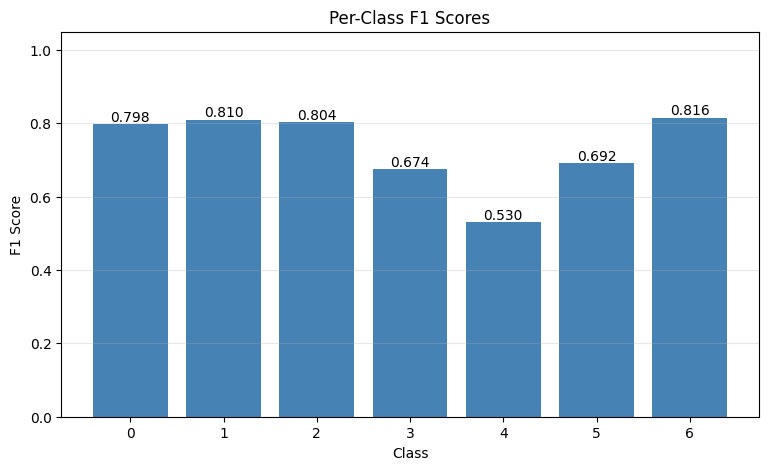

In [41]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    range(7),
    f1,
    color="steelblue"
)

plt.xlabel("Class")
plt.ylabel("F1 Score")
plt.title("Per-Class F1 Scores")

plt.xticks(range(7))

# Add values above bars
for bar, score in zip(bars, f1):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{score:.3f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.show()


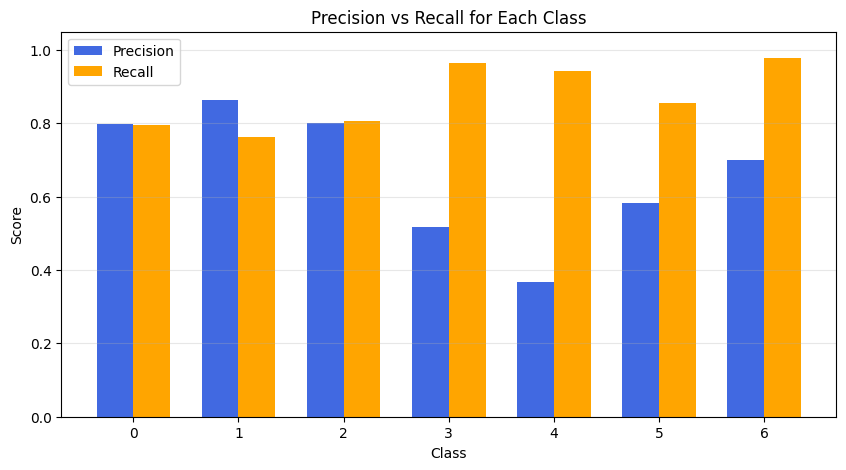

In [42]:
x = np.arange(7)

width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    precision,
    width,
    label="Precision",
    color="royalblue"
)

plt.bar(
    x + width/2,
    recall,
    width,
    label="Recall",
    color="orange"
)

plt.xlabel("Class")
plt.ylabel("Score")
plt.title("Precision vs Recall for Each Class")

plt.xticks(x)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()


In [43]:
true_counts = np.bincount(
    y_test,
    minlength=7
)

pred_counts = np.bincount(
    y_pred,
    minlength=7
)

print("True class distribution:")
print(true_counts)

print("\nPredicted class distribution:")
print(pred_counts)


True class distribution:
[21184 28331  3576   274   949  1737  2051]

Predicted class distribution:
[21115 25024  3610   509  2432  2551  2861]


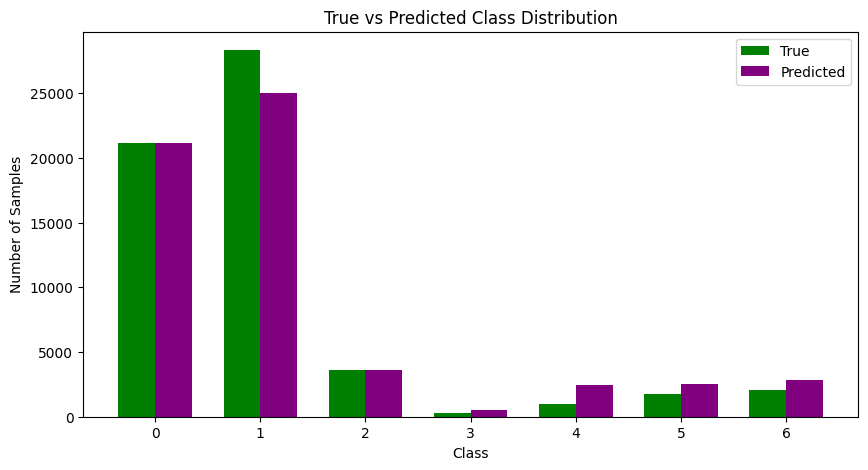

In [44]:
x = np.arange(7)

width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    true_counts,
    width,
    label="True",
    color="green"
)

plt.bar(
    x + width/2,
    pred_counts,
    width,
    label="Predicted",
    color="purple"
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("True vs Predicted Class Distribution")

plt.xticks(x)
plt.legend()

plt.show()


In [45]:
results = pd.DataFrame({
    "Class": range(7),
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
})

display(results)


,Class,Precision,Recall,F1 Score
0,0,0.799337,0.796733,0.798033
1,1,0.863971,0.763122,0.810421
2,2,0.799723,0.807327,0.803507
3,3,0.518664,0.963504,0.674330
4,4,0.368421,0.944152,0.530021
5,5,0.581733,0.854347,0.692164
6,6,0.700454,0.977084,0.815961


In [46]:
print(f"Overall Accuracy : {accuracy:.4f}")
print(f"Macro F1 Score   : {macro_f1:.4f}")


Overall Accuracy : 0.7923
Macro F1 Score   : 0.7321


In [47]:
print(f"Overall Accuracy : {accuracy:.4f}")
print(f"Macro F1 Score   : {macro_f1:.4f}")

display(results)


Overall Accuracy : 0.7923
Macro F1 Score   : 0.7321


,Class,Precision,Recall,F1 Score
0,0,0.799337,0.796733,0.798033
1,1,0.863971,0.763122,0.810421
2,2,0.799723,0.807327,0.803507
3,3,0.518664,0.963504,0.674330
4,4,0.368421,0.944152,0.530021
5,5,0.581733,0.854347,0.692164
6,6,0.700454,0.977084,0.815961


In [50]:
true_counts = np.bincount(y_test, minlength=7)
pred_counts = np.bincount(y_pred, minlength=7)

print("True class distribution:")
print(true_counts)

print("\nPredicted class distribution:")
print(pred_counts)


True class distribution:
[21184 28331  3576   274   949  1737  2051]

Predicted class distribution:
[21115 25024  3610   509  2432  2551  2861]
